# MarketPulse — Week 1: Market Data Exploration
**Author:** Mariam
**Project:** MarketPulse Graduation Project (DEPI)  
**Milestone:** Week 1 — Project & Data Specification (Sep 28 → Oct 4)  
**Dataset:** Daily Yahoo Finance Stock Prices (`data/raw/yahoo_prices_raw.csv`)

---

## Executive Summary & Objectives
As **Person 1 (Market Data & Quantitative Analysis)**, my role is to answer the fundamental question:
> **"What happened to each stock in the market?"**

Before performing data cleaning, feature engineering, and statistical modeling, Week 1 requires conducting an initial exploratory data analysis (EDA) of the raw market dataset to answer 6 mandatory questions:
1. **Number of companies**
2. **Number of rows**
3. **Date range**
4. **Missing values**
5. **Duplicate rows**
6. **Available columns**

This notebook inspects the raw data, executes these verification checks, visualizes market behavior, and provides the necessary foundation for Week 2 cleaning and downstream analytics.


### 1. Environment Setup & Library Imports
We import standard data analysis and visualization libraries: `pandas` for data manipulation, `numpy` for numerical operations, and `matplotlib` & `seaborn` for plotting.


In [1]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual styling for clean, professional charts
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

# Print confirmation
print(f"Pandas version: {pd.__version__}")
print(f"NumPy version: {np.__version__}")


Pandas version: 3.0.6
NumPy version: 2.5.4


### 2. Loading the Raw Market Dataset
The raw prices dataset was collected from Yahoo Finance and stored in `data/raw/yahoo_prices_raw.csv`. We load it into a pandas DataFrame and preview the first and last rows.


In [2]:
# Define path to raw data
raw_data_path = Path("../../data/raw/yahoo_prices_raw.csv")

if not raw_data_path.exists():
    # Fallback to local path if running from another directory
    raw_data_path = Path("data/raw/yahoo_prices_raw.csv")

# Load raw CSV
df_raw = pd.read_csv(raw_data_path)

print(f"Successfully loaded dataset from: {raw_data_path}")
print(f"Dataset Dimensions: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
df_raw.head(10)


Successfully loaded dataset from: ..\..\data\raw\yahoo_prices_raw.csv
Dataset Dimensions: 12,540 rows x 7 columns


,date,close,high,low,open,volume,ticker
0,2021-01-04,125.632507,129.709906,123.059860,129.622536,143301900,AAPL
1,2021-01-05,127.185760,127.894462,124.681070,125.127649,97664900,AAPL
2,2021-01-06,122.904518,127.224626,122.690939,123.991828,155088000,AAPL
3,2021-01-07,127.098457,127.787739,124.127781,124.613186,109578200,AAPL
4,2021-01-08,128.195435,128.758506,126.428554,128.564332,105158200,AAPL
5,2021-01-11,125.215057,126.370324,124.749073,125.418934,100384500,AAPL
6,2021-01-12,125.040314,125.904334,123.156940,124.749068,91951100,AAPL
7,2021-01-13,127.069313,127.612964,124.739375,125.001483,88636800,AAPL
8,2021-01-14,125.147102,127.176091,125.001472,126.981932,90221800,AAPL
9,2021-01-15,123.428764,126.418860,123.292852,125.020892,111598500,AAPL


Let's also inspect the tail of the dataset and the structural information including column data types and memory footprint.


In [3]:
# Inspect tail
df_raw.tail(5)


,date,close,high,low,open,volume,ticker
12535,2025-12-23,485.559998,491.970001,482.839996,489.399994,58223600,TSLA
12536,2025-12-24,485.399994,490.899994,476.799988,488.480011,41285400,TSLA
12537,2025-12-26,475.190002,489.089996,473.820007,485.230011,58780700,TSLA
12538,2025-12-29,459.640015,469.399994,459.000000,469.000000,66263000,TSLA
12539,2025-12-30,454.429993,463.119995,453.829987,461.089996,59238500,TSLA


In [4]:
# Structural schema info
df_raw.info()


<class 'pandas.DataFrame'>
RangeIndex: 12540 entries, 0 to 12539
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   date    12540 non-null  str    
 1   close   12540 non-null  float64
 2   high    12540 non-null  float64
 3   low     12540 non-null  float64
 4   open    12540 non-null  float64
 5   volume  12540 non-null  int64  
 6   ticker  12540 non-null  str    
dtypes: float64(4), int64(1), str(2)
memory usage: 685.9 KB


---
## 3. Mandatory Week 1 Task Questions & Direct Answers

Per the **MarketPulse Week 1 Tasks** specification, Person 1 must answer:
- **Number of companies:**
- **Number of rows:**
- **Date range:**
- **Missing values:**
- **Duplicate rows:**
- **Available columns:**

Below, we compute each metric programmatically and summarize the findings in an executive scorecard.


In [5]:
# 1. Number of companies
tickers = sorted(df_raw['ticker'].unique())
num_companies = len(tickers)

# 2. Number of rows
total_rows = len(df_raw)

# 3. Date range
df_raw['date_dt'] = pd.to_datetime(df_raw['date'])
min_date = df_raw['date_dt'].min().strftime('%Y-%m-%d')
max_date = df_raw['date_dt'].max().strftime('%Y-%m-%d')
total_calendar_days = (df_raw['date_dt'].max() - df_raw['date_dt'].min()).days
unique_trading_days = df_raw['date'].nunique()

# 4. Missing values
missing_counts = df_raw.isnull().sum()
total_missing = missing_counts.sum()

# 5. Duplicate rows
full_duplicates = df_raw.duplicated().sum()
key_duplicates = df_raw.duplicated(subset=['ticker', 'date']).sum()

# 6. Available columns
raw_columns = [col for col in df_raw.columns if col != 'date_dt']

# Build Scorecard Table
scorecard_data = [
    {"Question": "Number of companies", "Result": f"{num_companies} companies", "Details": f"Tickers: {', '.join(tickers)}"},
    {"Question": "Number of rows", "Result": f"{total_rows:,} rows", "Details": f"Exact balance of {total_rows // num_companies:,} rows per company"},
    {"Question": "Date range", "Result": f"{min_date} to {max_date}", "Details": f"{unique_trading_days:,} trading days across 5 full calendar years"},
    {"Question": "Missing values", "Result": f"{total_missing} missing values", "Details": "Complete dataset (0 nulls across all fields)"},
    {"Question": "Duplicate rows", "Result": f"{full_duplicates} duplicates", "Details": f"{key_duplicates} duplicate (ticker, date) composite keys"},
    {"Question": "Available columns", "Result": f"{len(raw_columns)} columns", "Details": f"{', '.join(raw_columns)}"}
]

df_scorecard = pd.DataFrame(scorecard_data)
df_scorecard


,Question,Result,Details
0,Number of companies,10 companies,"Tickers: AAPL, AMZN, JNJ, JPM, KO, LLY, MSFT, ..."
1,Number of rows,"12,540 rows","Exact balance of 1,254 rows per company"
2,Date range,2021-01-04 to 2025-12-30,"1,254 trading days across 5 full calendar years"
3,Missing values,0 missing values,Complete dataset (0 nulls across all fields)
4,Duplicate rows,0 duplicates,"0 duplicate (ticker, date) composite keys"
5,Available columns,7 columns,"date, close, high, low, open, volume, ticker"


### Detailed Audit of Missing Values & Data Types
Let's display the missing value breakdown and data types across every individual column.


In [6]:
# Detailed column-level audit
col_audit = pd.DataFrame({
    'Data Type': df_raw[raw_columns].dtypes,
    'Missing Count': df_raw[raw_columns].isnull().sum(),
    'Missing Pct (%)': (df_raw[raw_columns].isnull().sum() / len(df_raw)) * 100,
    'Unique Values': df_raw[raw_columns].nunique(),
    'Sample Value': df_raw[raw_columns].iloc[0]
})
col_audit


,Data Type,Missing Count,Missing Pct (%),Unique Values,Sample Value
date,str,0,0.0,1254,2021-01-04
close,float64,0,0.0,12253,125.632507
high,float64,0,0.0,12434,129.709906
low,float64,0,0.0,12443,123.05986
open,float64,0,0.0,12414,129.622536
volume,int64,0,0.0,12411,143301900
ticker,str,0,0.0,10,AAPL


---
## 4. Company & Sector Breakdown
In the **MarketPulse Data Model** (`docs/methodology/data_model.md`), `companies` serves as the core dimension table linking market prices, news articles, and corporate events.

Here is the full mapping of our 10 stocks with their company names, sector classifications, and sample counts in the raw dataset.


In [7]:
# Company mapping dictionary
company_info = {
    'AAPL': {'Company Name': 'Apple Inc.', 'Sector': 'Technology', 'Industry': 'Consumer Electronics'},
    'AMZN': {'Company Name': 'Amazon.com, Inc.', 'Sector': 'Consumer Cyclical', 'Industry': 'Internet Retail'},
    'JNJ':  {'Company Name': 'Johnson & Johnson', 'Sector': 'Healthcare', 'Industry': 'Pharmaceuticals'},
    'JPM':  {'Company Name': 'JPMorgan Chase & Co.', 'Sector': 'Financial Services', 'Industry': 'Diversified Banking'},
    'KO':   {'Company Name': 'The Coca-Cola Company', 'Sector': 'Consumer Defensive', 'Industry': 'Non-Alcoholic Beverages'},
    'LLY':  {'Company Name': 'Eli Lilly and Company', 'Sector': 'Healthcare', 'Industry': 'Pharmaceuticals'},
    'MSFT': {'Company Name': 'Microsoft Corporation', 'Sector': 'Technology', 'Industry': 'Software—Infrastructure'},
    'NVDA': {'Company Name': 'NVIDIA Corporation', 'Sector': 'Technology', 'Industry': 'Semiconductors'},
    'TSLA': {'Company Name': 'Tesla, Inc.', 'Sector': 'Consumer Cyclical', 'Industry': 'Auto Manufacturers'},
    'XOM':  {'Company Name': 'Exxon Mobil Corporation', 'Sector': 'Energy', 'Industry': 'Oil & Gas Integrated'}
}

# Ticker summary
ticker_summary = []
for t in tickers:
    sub = df_raw[df_raw['ticker'] == t]
    info = company_info.get(t, {})
    ticker_summary.append({
        'Ticker': t,
        'Company Name': info.get('Company Name', 'N/A'),
        'Sector': info.get('Sector', 'N/A'),
        'Rows': len(sub),
        'Min Date': sub['date'].min(),
        'Max Date': sub['date'].max(),
        'Min Close ($)': round(sub['close'].min(), 2),
        'Max Close ($)': round(sub['close'].max(), 2),
        'Avg Volume': int(sub['volume'].mean())
    })

df_companies_overview = pd.DataFrame(ticker_summary)
df_companies_overview


,Ticker,Company Name,Sector,Rows,Min Date,Max Date,Min Close ($),Max Close ($),Avg Volume
0,AAPL,Apple Inc.,Technology,1254,2021-01-04,2025-12-30,113.13,285.41,69849407
1,AMZN,"Amazon.com, Inc.",Consumer Cyclical,1254,2021-01-04,2025-12-30,81.82,254.00,57650085
2,JNJ,Johnson & Johnson,Healthcare,1254,2021-01-04,2025-12-30,131.51,210.78,8318995
3,JPM,JPMorgan Chase & Co.,Financial Services,1254,2021-01-04,2025-12-30,92.91,322.95,11147877
4,KO,The Coca-Cola Company,Consumer Defensive,1254,2021-01-04,2025-12-30,40.64,71.23,15257939
5,LLY,Eli Lilly and Company,Healthcare,1254,2021-01-04,2025-12-30,155.19,1104.60,3302005
6,MSFT,Microsoft Corporation,Technology,1254,2021-01-04,2025-12-30,202.38,537.65,25543214
7,NVDA,NVIDIA Corporation,Technology,1254,2021-01-04,2025-12-30,11.19,206.55,395096847
8,TSLA,"Tesla, Inc.",Consumer Cyclical,1254,2021-01-04,2025-12-30,108.10,489.88,99793947
9,XOM,Exxon Mobil Corporation,Energy,1254,2021-01-04,2025-12-30,33.25,118.61,19840977


### Trading Calendar Synchronization Check
A crucial check for quantitative financial analysis is verifying whether all companies share the exact same trading calendar dates. If one company is missing dates or has misaligned timestamps, cross-sectional calculations (such as beta, correlation matrices, and portfolio returns) will fail or become distorted.


In [8]:
# Verify that all tickers share identical trading date sequences
reference_dates = list(df_raw[df_raw['ticker'] == 'AAPL']['date'].sort_values())
is_synced = True

for t in tickers:
    t_dates = list(df_raw[df_raw['ticker'] == t]['date'].sort_values())
    if t_dates != reference_dates:
        is_synced = False
        print(f"Warning: {t} trading dates do not match the reference calendar!")

if is_synced:
    print(f"PASS: All 10 companies share the exact same {len(reference_dates):,} trading sessions in identical chronological order!")


PASS: All 10 companies share the exact same 1,254 trading sessions in identical chronological order!


---
## 5. Descriptive Statistics & Price Ranges
Let's inspect the statistical distributions of prices and trading volume across the entire 5-year observation window.


In [9]:
# Overall numerical summary
df_raw[['open', 'high', 'low', 'close', 'volume']].describe().T.round(2)


,count,mean,std,min,25%,50%,75%,max
open,12540.0,199.59,1.654700e+02,10.93,103.39,154.71,240.01,1.096700e+03
high,12540.0,202.04,1.676100e+02,11.69,104.50,156.20,243.76,1.106640e+03
low,12540.0,197.10,1.633200e+02,10.77,102.10,153.05,236.57,1.092820e+03
close,12540.0,199.65,1.655200e+02,11.19,103.38,154.63,240.22,1.104600e+03
volume,12540.0,70580129.69,1.276867e+08,932800.00,9912150.00,21975850.00,67647975.00,1.543911e+09


---
## 6. Visual Exploration: Market Behavior (Q1 Analysis)
MarketPulse analytical question **Q1** asks:
> **"How have selected stocks performed over time?"**

Below, we visualize:
1. **Raw Historical Close Prices**: Showing the nominal price trajectories of each stock.
2. **Normalized Performance (Base 100 on Jan 4, 2021)**: Comparing percentage growth side-by-side so that high-priced and low-priced stocks can be evaluated fairly on equal terms.


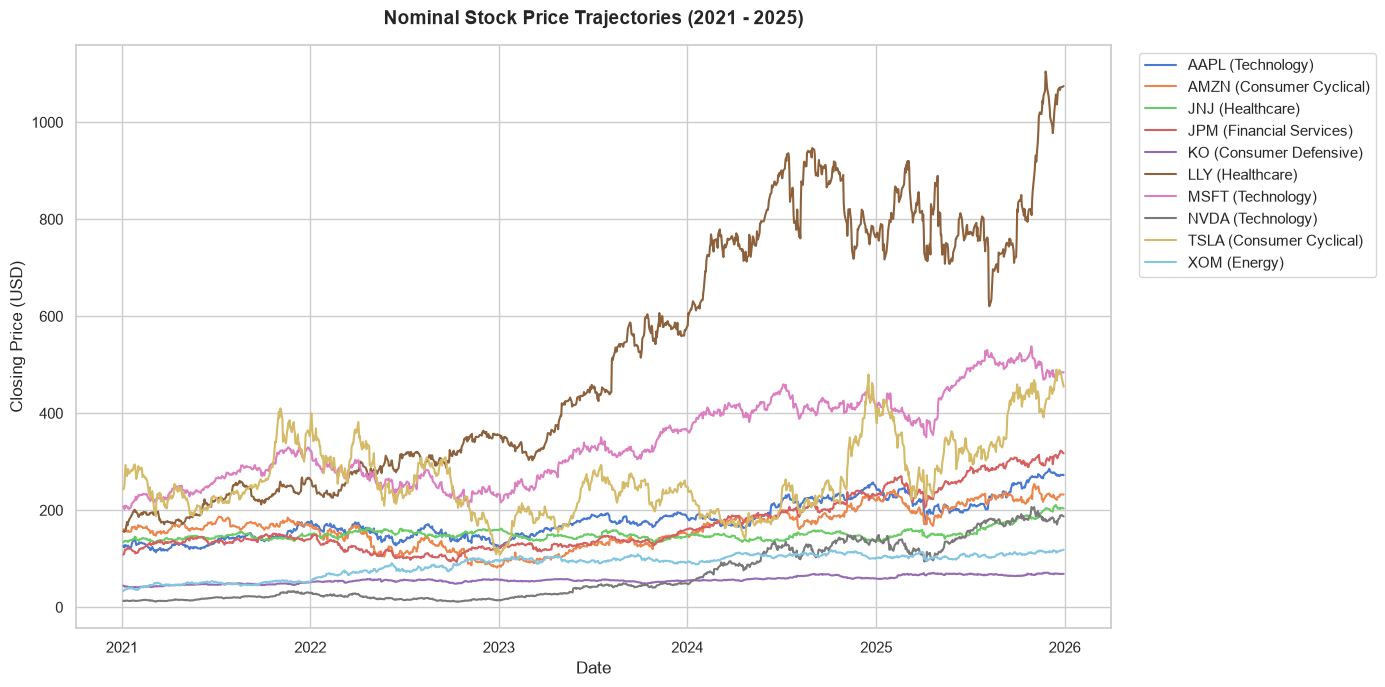

In [10]:
# Plot 1: Nominal Closing Prices
plt.figure(figsize=(14, 7))

for t in tickers:
    sub = df_raw[df_raw['ticker'] == t].sort_values('date_dt')
    plt.plot(sub['date_dt'], sub['close'], label=f"{t} ({company_info[t]['Sector']})", linewidth=1.5)

plt.title("Nominal Stock Price Trajectories (2021 - 2025)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Closing Price (USD)", fontsize=12)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)
plt.tight_layout()
plt.show()


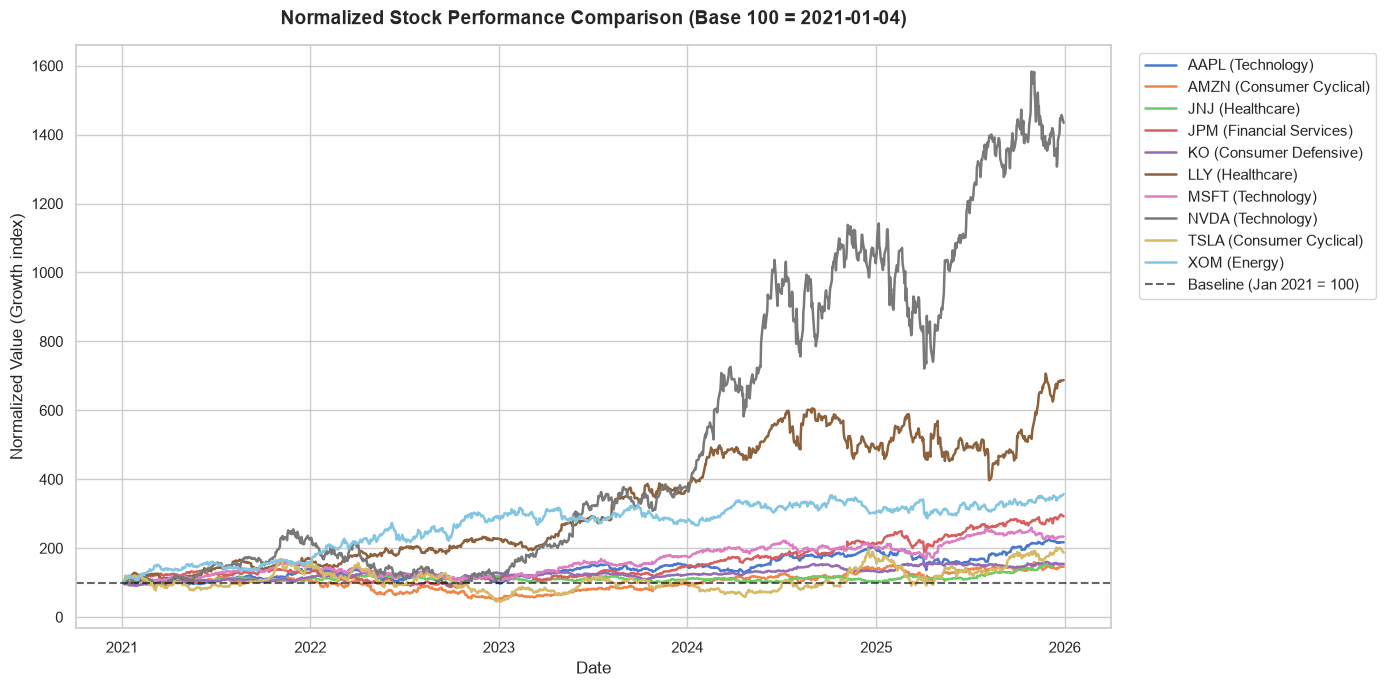

In [11]:
# Plot 2: Normalized Performance (Base = 100)
plt.figure(figsize=(14, 7))

for t in tickers:
    sub = df_raw[df_raw['ticker'] == t].sort_values('date_dt').copy()
    base_price = sub['close'].iloc[0]
    normalized_price = (sub['close'] / base_price) * 100
    plt.plot(sub['date_dt'], normalized_price, label=f"{t} ({company_info[t]['Sector']})", linewidth=1.8)

plt.axhline(100, color='black', linestyle='--', alpha=0.6, label='Baseline (Jan 2021 = 100)')
plt.title("Normalized Stock Performance Comparison (Base 100 = 2021-01-04)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Normalized Value (Growth index)", fontsize=12)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)
plt.tight_layout()
plt.show()


### Trading Volume & Liquidity Analysis
Trading volume indicates investor interest, market liquidity, and institutional trading pressure. We compare average daily volume and plot logarithmic distributions.


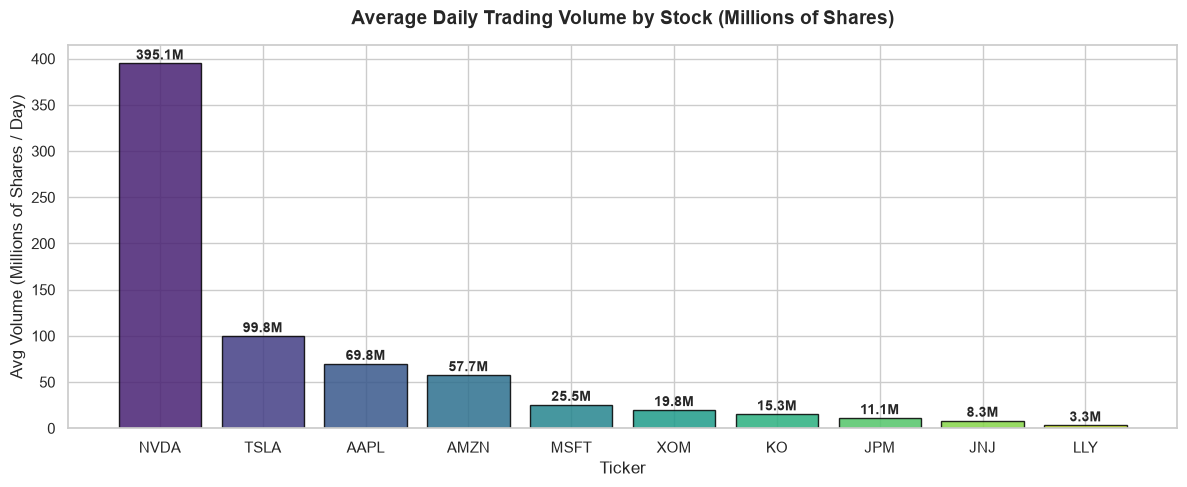

In [12]:
# Plot 3: Average Daily Trading Volume by Company
avg_vol = df_raw.groupby('ticker')['volume'].mean().sort_values(ascending=False)

plt.figure(figsize=(12, 5))
colors = sns.color_palette("viridis", len(avg_vol))
bars = plt.bar(avg_vol.index, avg_vol.values / 1e6, color=colors, edgecolor='black', alpha=0.85)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 1, f"{yval:.1f}M", ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.title("Average Daily Trading Volume by Stock (Millions of Shares)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Ticker", fontsize=12)
plt.ylabel("Avg Volume (Millions of Shares / Day)", fontsize=12)
plt.tight_layout()
plt.show()


---
## 7. Preliminary Data Quality & Anomaly Checks
To prepare for **Week 2: Data Cleaning**, we perform sanity checks on the raw prices:
1. **Price Positivity:** Are all prices strictly positive ($>0$)?
2. **High-Low Boundary:** Is `high` always greater than or equal to `low`?
3. **Open-Close Bounds:** Do `open` and `close` sit strictly within the `[low, high]` interval?
4. **Volume Non-Negativity:** Is `volume` always $\ge 0$?


In [13]:
# Anomaly checks
high_lt_low = df_raw[df_raw['high'] < df_raw['low']]
open_out_of_bounds = df_raw[(df_raw['open'] < df_raw['low'] - 1e-4) | (df_raw['open'] > df_raw['high'] + 1e-4)]
close_out_of_bounds = df_raw[(df_raw['close'] < df_raw['low'] - 1e-4) | (df_raw['close'] > df_raw['high'] + 1e-4)]
negative_prices = df_raw[(df_raw['open'] <= 0) | (df_raw['high'] <= 0) | (df_raw['low'] <= 0) | (df_raw['close'] <= 0)]
negative_volume = df_raw[df_raw['volume'] < 0]

print("=== DATA INTEGRITY AUDIT RESULTS ===")
print(f"High < Low violations:                 {len(high_lt_low)}")
print(f"Open out-of-bounds violations:         {len(open_out_of_bounds)}")
print(f"Close out-of-bounds violations:        {len(close_out_of_bounds)}")
print(f"Non-positive price records:            {len(negative_prices)}")
print(f"Negative volume records:               {len(negative_volume)}")

if len(high_lt_low) == 0 and len(open_out_of_bounds) == 0 and len(negative_prices) == 0:
    print("\nRESULT: Raw market data passed all initial physical integrity invariants!")


=== DATA INTEGRITY AUDIT RESULTS ===
High < Low violations:                 0
Open out-of-bounds violations:         0
Close out-of-bounds violations:        0
Non-positive price records:            0
Negative volume records:               0

RESULT: Raw market data passed all initial physical integrity invariants!


---
## 8. Summary of Week 1 Findings & Transition to Week 2

### Summary Scorecard
| Metric | Result | Interpretation |
|---|---|---|
| **Number of companies** | **10** | High-liquidity US large-caps across 5 sectors. |
| **Number of rows** | **12,540** | Exactly 1,254 trading days per company. Perfectly balanced panel. |
| **Date range** | **2021-01-04 to 2025-12-30** | 5 years of daily trading history. |
| **Missing values** | **0** | No imputation required for raw OHLCV fields. |
| **Duplicate rows** | **0** | No row-level deduplication needed, but uniqueness constraint must be enforced. |
| **Available columns** | **7** | `date`, `close`, `high`, `low`, `open`, `volume`, `ticker`. |
